# 데이터 전처리 기법 실습

### 1. 결측치 처리(Missing Data Handling)

결측치는 데이터에서 빠진 값을 말한다. 이를 처리하지 않으면 분석
결과가 왜곡될 수 있다. 결측치를 처리하는 방법은 크게 세 가지가
있다:
1. 삭제: 결측치가 포함된 행이나 열을 삭제한다. 데이터의 손실이
크지 않을 때 유용하다.
2. 대체: 결측치를 다른 값으로 채워 넣는다. 평균값, 중앙값, 최빈값
등으로 대체하거나, 더 복잡하게는 예측 모델을 사용해 결측치를 예
측하여 채울 수 있다.
3. 예측: 머신러닝 모델을 사용해 결측값을 예측하는 방법도 있다.

In [ ]:
# prompt: 결측치예제데이터.csv 읽어와서 데이터 프레임으로 출력하는 코드 만들어줘.

import pandas as pd

df = pd.read_csv('결측치예제데이터.csv')
df


,학생_ID,수학,영어,과학,사회
0,1,85.0,NaN,88.0,NaN
1,2,NaN,75.0,92.0,83.0
2,3,78.0,82.0,NaN,78.0
3,4,92.0,90.0,85.0,88.0
4,5,NaN,85.0,79.0,90.0
5,6,88.0,NaN,94.0,NaN
6,7,76.0,91.0,NaN,85.0
7,8,95.0,88.0,87.0,87.0
8,9,NaN,77.0,91.0,NaN
9,10,89.0,NaN,NaN,92.0


In [ ]:
# prompt: 아래 5가지 방식으로  결측치 제거 코드 만들어줘
# 1.삭제: 결측치가 있는 행이나 열을 삭제합니다.
# 2.평균값으로 대체: 결측치가 있는 열의 평균값으로 대체합니다.
# 3.중앙값으로 대체: 결측치가 있는 열의 중앙값으로 대체합니다.
# 4. 최빈값으로 대체: 결측치가 있는 열의 최빈값으로 대체합니다.
# 5. 특정 값으로 대체: 결측치를 특정 값으로 대체합니다.

# 1. 삭제: 결측치가 있는 행이나 열을 삭제합니다.
df_dropped_rows = df.dropna()
df_dropped_cols = df.dropna(axis=1)

# 2. 평균값으로 대체: 결측치가 있는 열의 평균값으로 대체합니다.
df_mean_filled = df.fillna(df.mean())

# 3. 중앙값으로 대체: 결측치가 있는 열의 중앙값으로 대체합니다.
df_median_filled = df.fillna(df.median())

# 4. 최빈값으로 대체: 결측치가 있는 열의 최빈값으로 대체합니다.
# 최빈값은 여러 개일 수 있으므로, 첫 번째 최빈값을 사용합니다.
df_mode_filled = df.fillna(df.mode().iloc[0])

# 5. 특정 값으로 대체: 결측치를 특정 값으로 대체합니다.
df_specific_filled = df.fillna(0) # 예시로 0으로 대체

print("결측치가 있는 행 삭제:\n", df_dropped_rows)
print("\n결측치가 있는 열 삭제:\n", df_dropped_cols)
print("\n평균값으로 대체:\n", df_mean_filled)
print("\n중앙값으로 대체:\n", df_median_filled)
print("\n최빈값으로 대체:\n", df_mode_filled)
print("\n특정 값(0)으로 대체:\n", df_specific_filled)


결측치가 있는 행 삭제:
    학생_ID    수학    영어    과학    사회
3      4  92.0  90.0  85.0  88.0
7      8  95.0  88.0  87.0  87.0

결측치가 있는 열 삭제:
    학생_ID
0      1
1      2
2      3
3      4
4      5
5      6
6      7
7      8
8      9
9     10

평균값으로 대체:
    학생_ID         수학    영어    과학         사회
0      1  85.000000  84.0  88.0  86.142857
1      2  86.142857  75.0  92.0  83.000000
2      3  78.000000  82.0  88.0  78.000000
3      4  92.000000  90.0  85.0  88.000000
4      5  86.142857  85.0  79.0  90.000000
5      6  88.000000  84.0  94.0  86.142857
6      7  76.000000  91.0  88.0  85.000000
7      8  95.000000  88.0  87.0  87.000000
8      9  86.142857  77.0  91.0  86.142857
9     10  89.000000  84.0  88.0  92.000000

중앙값으로 대체:
    학생_ID    수학    영어    과학    사회
0      1  85.0  85.0  88.0  87.0
1      2  88.0  75.0  92.0  83.0
2      3  78.0  82.0  88.0  78.0
3      4  92.0  90.0  85.0  88.0
4      5  88.0  85.0  79.0  90.0
5      6  88.0  85.0  94.0  87.0
6      7  76.0  91.0  88.0  85.0
7      8  

In [3]:
# prompt: 아래 5가지 방식으로  결측치 제거 코드 만들어줘
# 1.삭제: 결측치가 있는 행이나 열을 삭제합니다.
# 2.평균값으로 대체: 결측치가 있는 열의 평균값으로 대체합니다.
# 3.중앙값으로 대체: 결측치가 있는 열의 중앙값으로 대체합니다.
# 4. 최빈값으로 대체: 결측치가 있는 열의 최빈값으로 대체합니다.
# 5. 특정 값으로 대체: 결측치를 특정 값으로 대체합니다.

import pandas as pd

# Create a sample DataFrame with missing values
data = {'col1': [1, 2, None, 4, 5],
        'col2': [None, 2, 3, 4, 5],
        'col3': [1, 2, 3, None, 5],
        'col4': ['A', 'B', 'C', 'D', None]}
df = pd.DataFrame(data)

print("Original DataFrame:\n", df)

# 1. 삭제: 결측치가 있는 행이나 열을 삭제합니다.
df_dropped_rows = df.dropna()
df_dropped_cols = df.dropna(axis=1)

# 2. 평균값으로 대체: 결측치가 있는 열의 평균값으로 대체합니다.
# For numerical columns only
df_mean_filled = df.copy()
for col in df_mean_filled.select_dtypes(include=['number']).columns:
    df_mean_filled[col] = df_mean_filled[col].fillna(df_mean_filled[col].mean())

# 3. 중앙값으로 대체: 결측치가 있는 열의 중앙값으로 대체합니다.
# For numerical columns only
df_median_filled = df.copy()
for col in df_median_filled.select_dtypes(include=['number']).columns:
    df_median_filled[col] = df_median_filled[col].fillna(df_median_filled[col].median())

# 4. 최빈값으로 대체: 결측치가 있는 열의 최빈값으로 대체합니다.
# This can be applied to both numerical and categorical columns
df_mode_filled = df.copy()
for col in df_mode_filled.columns:
    mode_val = df_mode_filled[col].mode()
    if not mode_val.empty:
        df_mode_filled[col] = df_mode_filled[col].fillna(mode_val[0])

# 5. 특정 값으로 대체: 결측치를 특정 값으로 대체합니다.
df_specific_filled = df.fillna(-1) # Example: replace with -1 for numerical, 'Unknown' for categorical

print("\n1. 결측치가 있는 행 삭제:\n", df_dropped_rows)
print("\n1. 결측치가 있는 열 삭제:\n", df_dropped_cols)
print("\n2. 평균값으로 대체:\n", df_mean_filled)
print("\n3. 중앙값으로 대체:\n", df_median_filled)
print("\n4. 최빈값으로 대체:\n", df_mode_filled)
print("\n5. 특정 값(-1)으로 대체:\n", df_specific_filled)


Original DataFrame:
    col1  col2  col3  col4
0   1.0   NaN   1.0     A
1   2.0   2.0   2.0     B
2   NaN   3.0   3.0     C
3   4.0   4.0   NaN     D
4   5.0   5.0   5.0  None

1. 결측치가 있는 행 삭제:
    col1  col2  col3 col4
1   2.0   2.0   2.0    B

1. 결측치가 있는 열 삭제:
 Empty DataFrame
Columns: []
Index: [0, 1, 2, 3, 4]

2. 평균값으로 대체:
    col1  col2  col3  col4
0   1.0   3.5  1.00     A
1   2.0   2.0  2.00     B
2   3.0   3.0  3.00     C
3   4.0   4.0  2.75     D
4   5.0   5.0  5.00  None

3. 중앙값으로 대체:
    col1  col2  col3  col4
0   1.0   3.5   1.0     A
1   2.0   2.0   2.0     B
2   3.0   3.0   3.0     C
3   4.0   4.0   2.5     D
4   5.0   5.0   5.0  None

4. 최빈값으로 대체:
    col1  col2  col3 col4
0   1.0   2.0   1.0    A
1   2.0   2.0   2.0    B
2   1.0   3.0   3.0    C
3   4.0   4.0   1.0    D
4   5.0   5.0   5.0    A

5. 특정 값(-1)으로 대체:
    col1  col2  col3 col4
0   1.0  -1.0   1.0    A
1   2.0   2.0   2.0    B
2  -1.0   3.0   3.0    C
3   4.0   4.0  -1.0    D
4   5.0   5.0   5.0   -1


### 2. 이상치 처리(Outlier Handling)

In [5]:
# prompt: credit_card.xlsx 파일을 읽어서 박스 플롯 그려줘

import pandas as pd
import plotly.express as px

# 데이터 불러오기
df = pd.read_excel('credit_card.xlsx')

# 실제 데이터의 'AGE' 열을 사용하여 박스 플롯 그리기
fig = px.box(df, y="AGE")
fig.show()


In [6]:
# prompt: 이상치가 많은 순서대로 5개 컬럼의 이름과 각각의 이상치의 개수를 알려주는 코드.

outlier_counts = {}
for col in df.columns:
    if df[col].dtype in ['int64', 'float64']:  # 이상치 탐지는 수치형 데이터에만 적용
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # 이상치 개수 계산
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_counts[col] = len(outliers)

# 이상치가 많은 순서대로 정렬
sorted_outliers = sorted(outlier_counts.items(), key=lambda item: item[1], reverse=True)

# 상위 5개 컬럼과 이상치 개수 출력
print("이상치가 많은 순서대로 5개 컬럼 및 이상치 개수:")
for col_name, count in sorted_outliers[:5]:
    print(f"{col_name}: {count}개")


이상치가 많은 순서대로 5개 컬럼 및 이상치 개수:
default payment next month: 6636개
PAY_2: 4410개
PAY_3: 4209개
PAY_4: 3508개
PAY_0: 3130개


In [9]:
# prompt: default payment next month: 6636개
# PAY_2: 4410개
# PAY_3: 4209개
# PAY_4: 3508개
# PAY_0: 3130개
# 이 5개 의 컬럼을 각각 박스플롯 그려줘.

import pandas as pd
import plotly.express as px

# Assuming 'df' is already loaded and contains the relevant columns
# If not, you would load it like this:
# df = pd.read_csv('your_data.csv') or pd.read_excel('your_data.xlsx')

columns_to_plot = [
    'default payment next month',
    'PAY_2',
    'PAY_3',
    'PAY_4',
    'PAY_0'
]

for col in columns_to_plot:
    if col in df.columns:
        fig = px.box(df, y=col, title=f'Box plot for {col}')
        fig.show()
    else:
        print(f"Column '{col}' not found in the DataFrame.")


In [10]:
# prompt: PAY2,PAY_3,PAY_4,PAY_0 컬럼의 이상치를 포함한 데이터를 제거하는 코드

columns_to_remove_outliers = ['PAY_2', 'PAY_3', 'PAY_4', 'PAY_0']

df_no_outliers = df.copy()

for col in columns_to_remove_outliers:
    if col in df_no_outliers.columns and df_no_outliers[col].dtype in ['int64', 'float64']:
        Q1 = df_no_outliers[col].quantile(0.25)
        Q3 = df_no_outliers[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # 이상치를 포함하지 않는 데이터만 남김
        df_no_outliers = df_no_outliers[(df_no_outliers[col] >= lower_bound) & (df_no_outliers[col] <= upper_bound)]
    else:
        print(f"Column '{col}' not found or is not a numeric type. Skipping outlier removal for this column.")

print("\n이상치 제거 후 데이터 (PAY_2, PAY_3, PAY_4, PAY_0):")
df_no_outliers



이상치 제거 후 데이터 (PAY_2, PAY_3, PAY_4, PAY_0):


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
5,50000,1,1,2,37,0,0,0,0,0,...,19394,19619,20024,2500,1815,657,1000,1000,800,0
6,500000,1,1,2,29,0,0,0,0,0,...,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29993,100000,1,1,2,38,0,-1,-1,0,0,...,70626,69473,55004,2000,111784,4000,3000,2000,2000,0
29995,220000,1,3,1,39,0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,150000,1,3,2,43,-1,-1,-1,-1,0,...,8979,5190,0,1837,3526,8998,129,0,0,0
29998,80000,1,3,1,41,1,-1,0,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [11]:
# prompt: PAY2,PAY_3,PAY_4,PAY_0 컬럼의 이상치를 포함한 데이터를 제거해주고 제거된 데이터의 총 개수와 제거된 행 번호를 모두 알려주는 코드(한글로)

print("이상치 제거 전 데이터 개수:", len(df))

columns_to_remove_outliers = ['PAY_2', 'PAY_3', 'PAY_4', 'PAY_0']
outlier_indices = set()

for col in columns_to_remove_outliers:
    if col in df.columns and df[col].dtype in ['int64', 'float64']:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # 이상치인 행의 인덱스를 찾아서 추가
        col_outlier_indices = df[(df[col] < lower_bound) | (df[col] > upper_bound)].index.tolist()
        outlier_indices.update(col_outlier_indices)
    else:
        print(f"컬럼 '{col}'을 찾을 수 없거나 수치형이 아닙니다. 이 컬럼에 대한 이상치 제거를 건너뜁니다.")

# 이상치로 식별된 행들을 제거
df_no_outliers = df.drop(list(outlier_indices))

print("\n제거된 이상치 행 번호:", sorted(list(outlier_indices)))
print("제거된 이상치 데이터 총 개수:", len(outlier_indices))
print("\n이상치 제거 후 데이터 (PAY_2, PAY_3, PAY_4, PAY_0):")
df_no_outliers


이상치 제거 전 데이터 개수: 30000

제거된 이상치 행 번호: [0, 1, 8, 10, 13, 15, 16, 22, 31, 39, 44, 46, 50, 53, 54, 58, 62, 66, 67, 69, 71, 75, 83, 86, 89, 90, 102, 104, 110, 111, 112, 115, 117, 120, 123, 129, 135, 142, 147, 148, 158, 159, 160, 161, 163, 167, 175, 177, 179, 180, 185, 187, 189, 191, 193, 195, 199, 201, 213, 214, 217, 220, 224, 228, 229, 231, 233, 240, 243, 244, 250, 259, 269, 271, 276, 286, 288, 292, 293, 303, 308, 312, 313, 318, 320, 326, 327, 329, 330, 331, 332, 342, 354, 360, 362, 367, 369, 370, 372, 376, 381, 383, 387, 399, 404, 407, 410, 413, 420, 423, 426, 435, 449, 451, 456, 473, 477, 478, 481, 483, 491, 492, 497, 499, 501, 513, 514, 518, 526, 527, 529, 532, 533, 539, 542, 550, 557, 564, 575, 587, 598, 599, 603, 605, 613, 614, 644, 646, 648, 649, 659, 664, 668, 669, 670, 672, 673, 675, 676, 691, 692, 693, 697, 703, 704, 706, 707, 708, 712, 720, 724, 725, 729, 732, 739, 743, 748, 749, 751, 757, 760, 763, 774, 775, 778, 780, 781, 782, 790, 798, 801, 806, 807, 810, 814, 815, 816, 821, 

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
5,50000,1,1,2,37,0,0,0,0,0,...,19394,19619,20024,2500,1815,657,1000,1000,800,0
6,500000,1,1,2,29,0,0,0,0,0,...,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29993,100000,1,1,2,38,0,-1,-1,0,0,...,70626,69473,55004,2000,111784,4000,3000,2000,2000,0
29995,220000,1,3,1,39,0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,150000,1,3,2,43,-1,-1,-1,-1,0,...,8979,5190,0,1837,3526,8998,129,0,0,0
29998,80000,1,3,1,41,1,-1,0,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [12]:
# prompt: PAY2,PAY_3,PAY_4,PAY_0 컬럼의 이상치를 포함한 데이터를 제거해주고 이상치 제거후의 박스 플롯 그려줘.

import pandas as pd
import plotly.express as px

columns_to_remove_outliers = ['PAY_2', 'PAY_3', 'PAY_4', 'PAY_0']
outlier_indices = set()

for col in columns_to_remove_outliers:
    if col in df.columns and df[col].dtype in ['int64', 'float64']:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # 이상치인 행의 인덱스를 찾아서 추가
        col_outlier_indices = df[(df[col] < lower_bound) | (df[col] > upper_bound)].index.tolist()
        outlier_indices.update(col_outlier_indices)
    else:
        print(f"컬럼 '{col}'을 찾을 수 없거나 수치형이 아닙니다. 이 컬럼에 대한 이상치 제거를 건너뜁니다.")

# 이상치로 식별된 행들을 제거
df_no_outliers = df.drop(list(outlier_indices))

print("\n이상치 제거 후 데이터 (PAY_2, PAY_3, PAY_4, PAY_0):")
print(df_no_outliers)

print("\n이상치 제거 후 박스 플롯:")
for col in columns_to_remove_outliers:
    if col in df_no_outliers.columns:
        fig = px.box(df_no_outliers, y=col, title=f'Box plot for {col} (Outliers Removed)')
        fig.show()
    else:
        print(f"Column '{col}' not found in the DataFrame after outlier removal.")


이상치 제거 후 데이터 (PAY_2, PAY_3, PAY_4, PAY_0):
       LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
2          90000    2          2         2   34      0      0      0      0   
3          50000    2          2         1   37      0      0      0      0   
4          50000    1          2         1   57     -1      0     -1      0   
5          50000    1          1         2   37      0      0      0      0   
6         500000    1          1         2   29      0      0      0      0   
...          ...  ...        ...       ...  ...    ...    ...    ...    ...   
29993     100000    1          1         2   38      0     -1     -1      0   
29995     220000    1          3         1   39      0      0      0      0   
29996     150000    1          3         2   43     -1     -1     -1     -1   
29998      80000    1          3         1   41      1     -1      0      0   
29999      50000    1          2         1   46      0      0      0      0   

       

In [13]:
# prompt: 표준화예제데이터.csv 이 데이터를 표준화해서 출력해줘

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Load the dataset
df_std = pd.read_csv('표준화예제데이터.csv')

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit and transform the data
# We select only numeric columns for standardization
numeric_cols = df_std.select_dtypes(include=['int64', 'float64']).columns
df_std_scaled = scaler.fit_transform(df_std[numeric_cols])

# Convert the scaled data back to a DataFrame
df_std_scaled = pd.DataFrame(df_std_scaled, columns=numeric_cols)

print("Original DataFrame:\n", df_std)
print("\nStandardized DataFrame:\n", df_std_scaled)

Original DataFrame:
     feature1  feature2  feature3
0        685        85       876
1        560       204       270
2        630       325       881
3        193       775       297
4        836       965       329
..       ...       ...       ...
95       612       638       980
96       566       771       218
97       909       516       664
98       634        95       822
99       939       227       308

[100 rows x 3 columns]

Standardized DataFrame:
     feature1  feature2  feature3
0   0.561420 -1.299977  1.253192
1   0.124558 -0.908903 -0.830076
2   0.369201 -0.511256  1.270381
3  -1.158068  0.967597 -0.737257
4   1.089149  1.592001 -0.627249
..       ...       ...       ...
95  0.306292  0.517368  1.610717
96  0.145527  0.954451 -1.008838
97  1.344276  0.116435  0.524392
98  0.383180 -1.267114  1.067554
99  1.449123 -0.833317 -0.699442

[100 rows x 3 columns]


In [15]:
!pwd

/content


In [16]:
!ls

credit_card.xlsx  결측치예제데이터.csv	표준화예제데이터.csv


In [17]:
# prompt: 표준화예제데이터.csv 이 데이터를 정규화해서 출력해줘.

from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Load the dataset
df_norm = pd.read_csv('표준화예제데이터.csv')

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Fit and transform the data
# We select only numeric columns for normalization
numeric_cols = df_norm.select_dtypes(include=['int64', 'float64']).columns
df_norm_scaled = scaler.fit_transform(df_norm[numeric_cols])

# Convert the scaled data back to a DataFrame
df_norm_scaled = pd.DataFrame(df_norm_scaled, columns=numeric_cols)

print("Original DataFrame:\n", df_norm)
print("\nNormalized DataFrame:\n", df_norm_scaled)

Original DataFrame:
     feature1  feature2  feature3
0        685        85       876
1        560       204       270
2        630       325       881
3        193       775       297
4        836       965       329
..       ...       ...       ...
95       612       638       980
96       566       771       218
97       909       516       664
98       634        95       822
99       939       227       308

[100 rows x 3 columns]

Normalized DataFrame:
     feature1  feature2  feature3
0   0.692308  0.075884  0.875380
1   0.564103  0.199584  0.261398
2   0.635897  0.325364  0.880446
3   0.187692  0.793139  0.288754
4   0.847179  0.990644  0.321175
..       ...       ...       ...
95  0.617436  0.650728  0.980750
96  0.570256  0.788981  0.208713
97  0.922051  0.523909  0.660588
98  0.640000  0.086279  0.820669
99  0.952821  0.223493  0.299899

[100 rows x 3 columns]


In [19]:
# prompt: 레이블인코딩예제데이터.csv 범주형 컬럼을 레이블 인코딩 처리해줘.
# 레이블 인코딩된 문자와 숫자 매핑값을 각 컬럼별로 알려줘.

from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Load the dataset
df_label = pd.read_csv('레이블인코딩예제데이터.csv')

# Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Dictionary to store the mapping for each column
label_encoding_maps = {}

# Iterate over each column in the DataFrame
for col in df_label.columns:
    # Check if the column is of object type (categorical)
    if df_label[col].dtype == 'object':
        # Fit and transform the column
        df_label[col] = label_encoder.fit_transform(df_label[col])

        # Store the mapping for this column
        # classes_ attribute stores the unique labels encountered
        # mapping is created as a dictionary: {label: encoded_value}
        label_encoding_maps[col] = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

print("Original DataFrame:\n", pd.read_csv('레이블인코딩예제데이터.csv')) # Display original for comparison
print("\nLabel Encoded DataFrame:\n", df_label)

print("\nLabel Encoding Maps:")
for col, mapping in label_encoding_maps.items():
    print(f"Column '{col}': {mapping}")


Original DataFrame:
     feature_1 feature_2  feature_3 feature_4  label
0         103    medium      0.493         C    cat
1         436     small      0.041         A  mouse
2         861     small      0.157         E    dog
3         271      huge      0.015         B  mouse
4         107    medium      0.813         C  mouse
5          72      tiny      0.065         A    dog
6         701    medium      0.857         B    cat
7          21      tiny      0.839         B    cat
8         615      huge      0.521         D    dog
9         122       big      0.344         E    cat
10        467     small      0.129         C    dog
11        215      huge      0.648         A    dog
12        331     small      0.472         D  mouse
13        459       big      0.063         E    dog
14         88       big      0.139         D  mouse
15        373      huge      0.499         E    cat
16        100       big      0.593         E    cat
17        872      tiny      0.392         

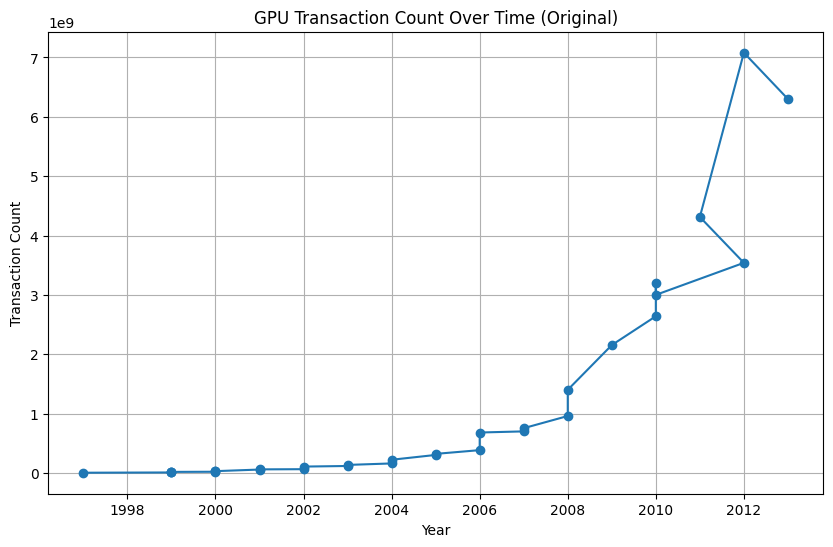

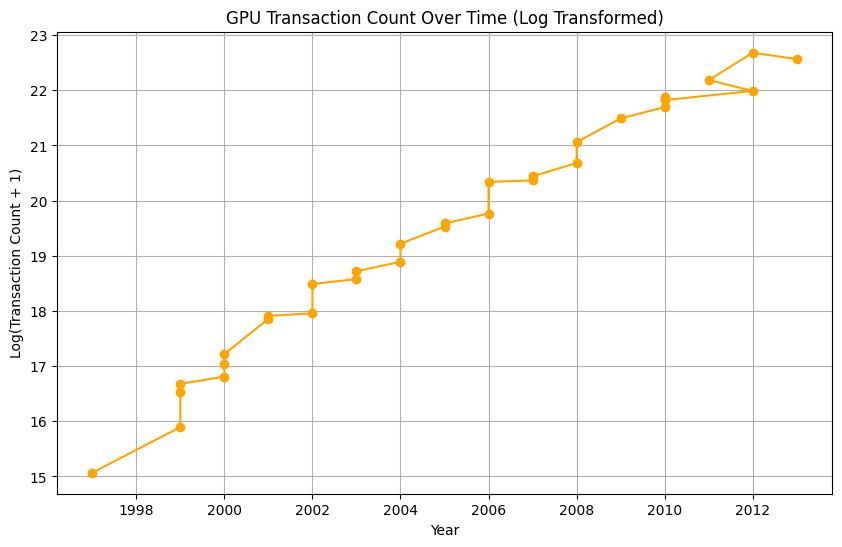

In [21]:
# prompt: gpu_transcount.csv 그래프로 출력해줘.
# 로그 변환한 뒤 그래프로 출력해줘.

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the dataset
df = pd.read_csv('gpu_transcount.csv')

# Plot the original data using corrected column names
plt.figure(figsize=(10, 6))
plt.plot(df['year'], df['gpu_trans_count'], marker='o')
plt.title('GPU Transaction Count Over Time (Original)')
plt.xlabel('Year')
plt.ylabel('Transaction Count')
plt.grid(True)
plt.show()

# Apply log transformation to 'gpu_trans_count'
# Add a small constant to avoid log(0) if it can be zero
df['gpu_trans_count_log'] = np.log1p(df['gpu_trans_count'])

# Plot the log-transformed data
plt.figure(figsize=(10, 6))
plt.plot(df['year'], df['gpu_trans_count_log'], marker='o', color='orange')
plt.title('GPU Transaction Count Over Time (Log Transformed)')
plt.xlabel('Year')
plt.ylabel('Log(Transaction Count + 1)')
plt.grid(True)
plt.show()


Archive:  archive.zip
replace README.md? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
Original dataset shape Counter({"'0'": 284315, "'1'": 492})
Resampled dataset shape Counter({"'0'": 284315, "'1'": 284315})


/tmp/ipykernel_5321/4000211565.py:32: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_5321/4000211565.py:38: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




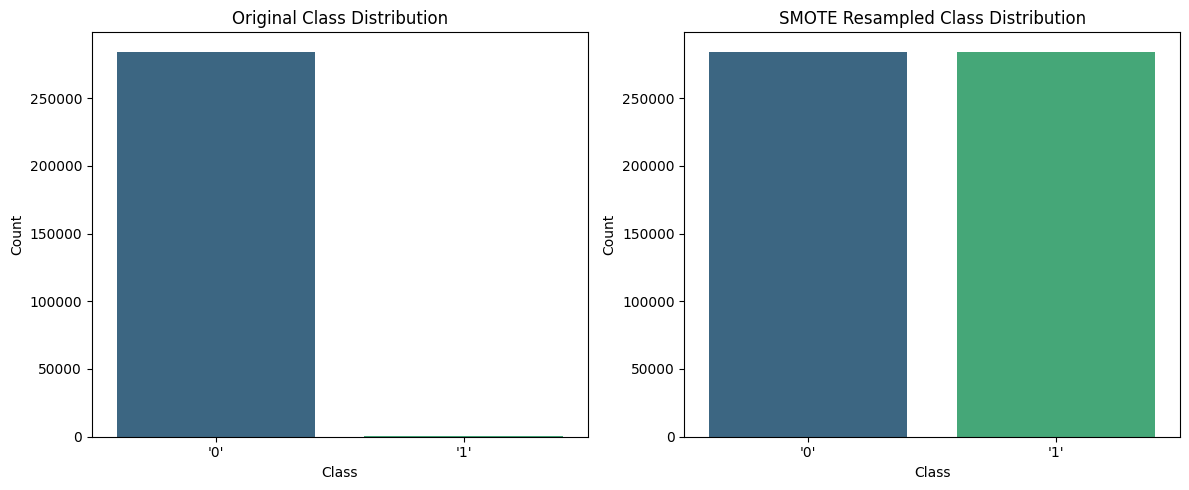

In [28]:
# prompt: archive.zip  파일을 압축풀어 Credit Card Fraud Detection 데이터를
# SMOTE로 오버샘플링해서 분포를 출력하는 코드를 구현해줘

!unzip archive.zip
import pandas as pd
from imblearn.over_sampling import SMOTE
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('./archive/creditcard.csv')

# Separate features and target
X = df.drop('Class', axis=1)
y = df['Class']

# Display the original class distribution
print("Original dataset shape %s" % Counter(y))

# Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Display the class distribution after SMOTE
print("Resampled dataset shape %s" % Counter(y_resampled))

# Plot the distribution before and after SMOTE
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(x=y, palette='viridis')
plt.title('Original Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.countplot(x=y_resampled, palette='viridis')
plt.title('SMOTE Resampled Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')

plt.tight_layout()
plt.show()
